# STEP 7 · I-MOD 예비 권역 운영 적합성 및 선정 민감도 검증
**기준:** 286개 정류장군 전체는 원본에 유지. STEP 6에서 공간 후보로 추린 40개 정류장군(12개 다중 정류장 권역 + 14개 단독 후보)을 26개 후보 단위로 평가.

- 승차량은 **실제 I-MOD 호출 수요가 아니며**, 운행횟수는 **차량 수용력이나 배차간격이 아님**.
- 시간대별 수요 비중 − 운행 비중은 **상대적 불일치**로만 해석. 실제 공급부족/미충족 수요를 의미하지 않음.
- 6월 11일은 의도적 제외. 물리 정류장 ID별 수요 분할 금지.
- 이번 선정은 **예비 권역의 검토 우선순위**이지 확정 노선·서비스 도입 권고가 아님.

## 1. 입력 업로드 및 검사
**정확히 두 파일**: `05_complete500_assignments.csv`(STEP 6), `04_StopGroup_Hourly_2026Q2.csv`(시간대별 통합본). 중복 업로드명 `(1)`도 허용.

In [1]:
import io, re, os, zipfile
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
OUT = Path('IMOD_STEP7_Results'); OUT.mkdir(exist_ok=True)
try:
 from google.colab import files
 print('STEP6 assignments CSV와 StopGroup Hourly CSV 두 파일을 업로드하세요.')
 uploaded = files.upload()
except ImportError:
 uploaded={}

def load_file(marker, fallback):
 matches = [(n,b) for n,b in uploaded.items() if marker.lower() in n.lower()]
 if matches:
  name,blob=sorted(matches,key=lambda z:len(z[0]))[0]
  print('선택:',name)
  return pd.read_csv(io.BytesIO(blob), encoding='utf-8-sig')
 p=Path(fallback)
 if p.exists():
  print('로컬 입력:',p);return pd.read_csv(p)
 raise FileNotFoundError(f'{marker} 파일이 없습니다. 정확한 파일을 업로드하세요.')

assign = load_file('complete500_assignments','/mnt/data/IMOD_STEP6_Results/05_complete500_assignments.csv')
hourly = load_file('StopGroup_Hourly','/mnt/data/IMOD_StopGroups_2026Q2/04_StopGroup_Hourly_2026Q2.csv')
assert len(assign)==40, f'STEP6 후보 40개가 아님: {len(assign)}'
assert assign.station_name.is_unique
assert hourly.station_name.nunique()==286
assert hourly[['date','station_name','hour']].duplicated().sum()==0
hourly['date']=pd.to_datetime(hourly['date'].astype(str),format='%Y%m%d')
assert hourly.date.nunique()==90
print('전체 원본 정류장군:',hourly.station_name.nunique(),'| 권역 선정 대상:',len(assign),'| 공간 후보 단위:',assign.zone_id.nunique())


STEP6 assignments CSV와 StopGroup Hourly CSV 두 파일을 업로드하세요.


Saving 04_StopGroup_Hourly_2026Q2.csv to 04_StopGroup_Hourly_2026Q2.csv
Saving 05_complete500_assignments.csv to 05_complete500_assignments.csv
선택: 05_complete500_assignments.csv
선택: 04_StopGroup_Hourly_2026Q2.csv
전체 원본 정류장군: 286 | 권역 선정 대상: 40 | 공간 후보 단위: 26


## 2. 26개 예비 권역별 특징
정류장군 통계를 권역별로 합산하되, `unique_route_count`는 정류장군 합산 시 노선 중복 문제가 있어 **합산하지 않음**. 권역의 최소·최대·평균과 노선 접근성은 참고 정보로 보존.

In [2]:
assert set(assign.station_name).issubset(set(hourly.station_name))
agg=assign.groupby('zone_id',sort=True).agg(
 n_stops=('station_name','size'),names=('station_name',lambda x:' | '.join(x)),
 daily_demand=('avg_daily_passengers','sum'),daily_ops=('avg_daily_operations','sum'),
 median_mismatch=('temporal_mismatch','median'),mean_mismatch=('temporal_mismatch','mean'),
 mean_score=('score_base','mean'),median_low_supply=('low_supply_hour_ratio_lt1avg','median'),
 max_routes_at_stop=('unique_route_count','max'),median_routes_at_stop=('unique_route_count','median'),
 repeat_max=('top20_frequency','max'),repeat_count=('top20_frequency',lambda x:int((x>=2).sum())),
 min_rank=('rank_base','min'),cluster_count=('KMeans_FULL8','nunique')
).reset_index()
agg['type']=np.where(agg.n_stops>=2,'multi','single')
agg['passengers_per_operation_zone']=agg.daily_demand/agg.daily_ops.replace(0,np.nan)
agg.to_csv(OUT/'01_zone_base_profiles.csv',index=False,encoding='utf-8-sig')
display(agg.sort_values('mean_score',ascending=False).head(12))


,zone_id,n_stops,names,daily_demand,daily_ops,median_mismatch,mean_mismatch,mean_score,median_low_supply,max_routes_at_stop,median_routes_at_stop,repeat_max,repeat_count,min_rank,cluster_count,type,passengers_per_operation_zone
5,Z06,1,롯데백화점(인천터미널),10306.455556,2553.288889,0.230978,0.230978,72.132867,0.166667,26.0,26.0,3,1,5,1,single,4.036541
0,Z01,1,문학경기장(야구장),309.477778,456.133333,0.411426,0.411426,69.318182,0.208333,7.0,7.0,2,1,7,1,single,0.678481
1,Z02,1,문학초등학교,925.788889,554.244444,0.186875,0.186875,67.290210,0.208333,4.0,4.0,3,1,12,1,single,1.670362
18,Z19,1,용현3동행정복지센터.보훈병원,1206.344444,716.677778,0.180046,0.180046,67.220280,0.208333,5.0,5.0,3,1,13,1,single,1.683245
22,Z23,2,남중학교 | 인화여고,1042.666667,1628.300000,0.237839,0.237839,66.608392,0.208333,9.0,7.0,3,1,3,1,multi,0.640341
9,Z10,2,주안7동행정복지센터 | 신기.남부종합시장(진흥사거리),3791.100000,1909.466666,0.184173,0.184173,65.340909,0.187500,8.0,7.0,3,2,18,2,multi,1.985424
21,Z22,2,주안역 | 주안역환승정류장,11853.111111,2257.433333,0.191644,0.191644,64.274476,0.166667,17.0,13.0,3,1,10,1,multi,5.250703
10,Z11,1,인천소방본부,735.011111,911.733333,0.208052,0.208052,64.265734,0.208333,6.0,6.0,1,0,23,1,single,0.806169
12,Z13,2,한양아파트 | 토지금고시장,869.466667,528.877778,0.203655,0.203655,63.321678,0.208333,6.0,4.0,2,1,15,1,multi,1.643984
15,Z16,1,인천고등학교,548.366667,717.488889,0.215537,0.215537,63.041958,0.208333,7.0,7.0,0,0,31,1,single,0.764286


## 3. 월별·시간별 독립 집계 및 품질검사

In [3]:
h=hourly[hourly.station_name.isin(assign.station_name)].merge(assign[['station_name','zone_id']],on='station_name',how='left',validate='many_to_one')
h['month']=h.date.dt.month
month_days=h[['date','month']].drop_duplicates().groupby('month').size()
print('월별 유효 관측일:',month_days.to_dict())
assert month_days.to_dict()=={4:30,5:31,6:29}
monthly=h.groupby(['zone_id','month'],as_index=False).agg(riders=('passenger_count','sum'),operations=('operation_count','sum'))
monthly['observed_days']=monthly.month.map(month_days)
monthly['daily_riders']=monthly.riders/monthly.observed_days
monthly['daily_operations']=monthly.operations/monthly.observed_days
monthly.to_csv(OUT/'02_monthly_zone_profiles.csv',index=False,encoding='utf-8-sig')
summary=monthly.groupby('zone_id').agg(monthly_mean=('daily_riders','mean'),monthly_std=('daily_riders','std'),monthly_min=('daily_riders','min'),monthly_max=('daily_riders','max')).reset_index()
summary['monthly_cv']=summary.monthly_std/summary.monthly_mean.replace(0,np.nan)
summary['monthly_min_max_ratio']=summary.monthly_min/summary.monthly_max.replace(0,np.nan)
agg=agg.merge(summary[['zone_id','monthly_cv','monthly_min_max_ratio']],on='zone_id',validate='one_to_one')

# 승차량>0, 운행=0 현상은 결측/시차/통계집계 가능성을 남겨두고 별도 계수
quality=h.assign(flag=(h.passenger_count>0)&(h.operation_count==0)).groupby('zone_id',as_index=False).agg(zero_op_positive_demand=('flag','sum'))
agg=agg.merge(quality,on='zone_id',validate='one_to_one')
print('후보에 포함된 승객 양수·운행 0 기록 합:',agg.zero_op_positive_demand.sum())


월별 유효 관측일: {4: 30, 5: 31, 6: 29}
후보에 포함된 승객 양수·운행 0 기록 합: 596


## 4. 시간대별 상대 불일치 계산
평균 일간 시간대 승차·운행 건수의 비중을 비교. **비중 차이가 높아도 실제 운행 부족을 증명하지 않음**.

In [4]:
hours=h.groupby(['zone_id','hour'],as_index=False)[['passenger_count','operation_count']].sum()
hours['demand_share']=hours.passenger_count/hours.groupby('zone_id').passenger_count.transform('sum').replace(0,np.nan)
hours['supply_share']=hours.operation_count/hours.groupby('zone_id').operation_count.transform('sum').replace(0,np.nan)
hours['relative_gap']=hours.demand_share-hours.supply_share
hours.to_csv(OUT/'03_hourly_zone_shares.csv',index=False,encoding='utf-8-sig')
# total variation distance: 단순 시간적 불일치의 참고용. 원래 정류장별 mismatch와 혼동 금지.
ref=hours.groupby('zone_id',as_index=False).agg(
 positive_gap_sum=('relative_gap',lambda x:x.clip(lower=0).sum()),
 max_positive_gap=('relative_gap','max'),
)
idx=hours.groupby('zone_id').relative_gap.idxmax()
peaks=hours.loc[idx,['zone_id','hour','relative_gap','passenger_count','operation_count']].rename(columns={'hour':'peak_hour','relative_gap':'peak_hour_gap','passenger_count':'peak_hour_riders_90d','operation_count':'peak_hour_ops_90d'})
agg=agg.merge(ref,on='zone_id').merge(peaks,on='zone_id')
assert (agg.positive_gap_sum<=1.00001).all()
print('최대 상대 차이가 발생한 권역:')
display(agg.sort_values('peak_hour_gap',ascending=False)[['zone_id','names','peak_hour','peak_hour_gap','daily_demand']].head(8))


최대 상대 차이가 발생한 권역:


,zone_id,names,peak_hour,peak_hour_gap,daily_demand
3,Z04,관교중학교(약수터),15,0.178517,414.955556
0,Z01,문학경기장(야구장),21,0.173158,309.477778
6,Z07,시티오씨엘4단지 | 힐스테이트학익104동앞,7,0.104145,869.066667
23,Z24,공단시장 | 태화아파트,7,0.098257,631.211111
1,Z02,문학초등학교,7,0.090125,925.788889
24,Z25,서화초등학교(도화역금강펜테리움),8,0.084413,350.488889
22,Z23,남중학교 | 인화여고,16,0.077711,1042.666667
10,Z11,인천소방본부,7,0.076220,735.011111


## 5. 권역별 우선순위 및 4~6개 후보 민감도
수요, 불일치, 공급 취약성, 월별 변동, 시나리오 반복 선정 여부를 **동일 26개 후보 안에서** 백분위로 변환한다. 후보 점수는 정책적 가정이며 실제 미충족 수요가 아니다.

단일 정류장군과 다중 정류장군의 수요 합계는 구성 정류장 수에 영향을 받으므로, 결과를 `multi`/`single` 유형별로 분리해서 확인한다.

In [5]:
def pct(s):return s.rank(pct=True,method='average').mul(100)
for name,source in [
 ('demand','daily_demand'),('mismatch','positive_gap_sum'),
 ('low_supply','median_low_supply'),('repeat','repeat_count'),
 ('month_stable','monthly_min_max_ratio'),('service_intensity','passengers_per_operation_zone')]:
 agg['p_'+name]=pct(agg[source].fillna(agg[source].median()))
weights={
 'balanced':{'demand':.25,'mismatch':.30,'low_supply':.20,'repeat':.15,'month_stable':.10},
 'demand_priority':{'demand':.45,'mismatch':.20,'low_supply':.15,'repeat':.10,'month_stable':.10},
 'time_priority':{'demand':.15,'mismatch':.45,'low_supply':.20,'repeat':.10,'month_stable':.10},
 'robustness_priority':{'demand':.20,'mismatch':.25,'low_supply':.10,'repeat':.25,'month_stable':.20},
}
for scenario,ws in weights.items():
 agg['score_'+scenario]=sum(agg['p_'+v]*w for v,w in ws.items())
 agg['rank_'+scenario]=agg['score_'+scenario].rank(ascending=False,method='min').astype(int)
 agg['top6_'+scenario]=agg['rank_'+scenario]<=6
agg['top6_frequency']=agg[[f'top6_{k}' for k in weights]].sum(axis=1)
agg['median_rank']=agg[[f'rank_{k}' for k in weights]].median(axis=1)
agg['mean_rank']=agg[[f'rank_{k}' for k in weights]].mean(axis=1)
# 기준: 반복 포함 > 전형별 상대 순위, 평균 순위 동률 해소
agg=agg.sort_values(['top6_frequency','median_rank','score_balanced'],ascending=[False,True,False])
agg['provisional_review_order']=range(1,len(agg)+1)
agg.to_csv(OUT/'04_all_26_zones_scenario_scores.csv',index=False,encoding='utf-8-sig')
selected=agg.head(6).copy()
selected.to_csv(OUT/'05_provisional_top6_review.csv',index=False,encoding='utf-8-sig')
display(selected[['zone_id','type','names','daily_demand','positive_gap_sum','monthly_cv','top6_frequency','median_rank']])


,zone_id,type,names,daily_demand,positive_gap_sum,monthly_cv,top6_frequency,median_rank
5,Z06,single,롯데백화점(인천터미널),10306.455556,0.230978,0.010893,4,1.0
22,Z23,multi,남중학교 | 인화여고,1042.666667,0.203813,0.049635,4,4.0
9,Z10,multi,주안7동행정복지센터 | 신기.남부종합시장(진흥사거리),3791.100000,0.183314,0.018967,3,2.0
21,Z22,multi,주안역 | 주안역환승정류장,11853.111111,0.182852,0.038981,2,5.0
0,Z01,single,문학경기장(야구장),309.477778,0.411426,0.112066,2,6.5
1,Z02,single,문학초등학교,925.788889,0.186875,0.039313,2,7.5


## 6. 단독 후보 보호 및 가중치 안정성
상위 6개로 자동 확정하지 않는다. 다중 정류장 권역과 단독 후보를 별도 확인하여 단독 고득점 후보가 누락되지 않는지 검증한다.

다중 정류장 권역 상위 6개:


,zone_id,names,top6_frequency,median_rank,daily_demand
22,Z23,남중학교 | 인화여고,4,4.0,1042.666667
9,Z10,주안7동행정복지센터 | 신기.남부종합시장(진흥사거리),3,2.0,3791.100000
21,Z22,주안역 | 주안역환승정류장,2,5.0,11853.111111
6,Z07,시티오씨엘4단지 | 힐스테이트학익104동앞,2,8.0,869.066667
14,Z15,주안남초등학교 | 힐스테이트푸르지오주안 | 국민건강보험남부지사,1,10.5,2387.822222
23,Z24,공단시장 | 태화아파트,1,11.5,631.211111


단독 후보 상위 6개:


,zone_id,names,top6_frequency,median_rank,daily_demand
5,Z06,롯데백화점(인천터미널),4,1.0,10306.455556
0,Z01,문학경기장(야구장),2,6.5,309.477778
1,Z02,문학초등학교,2,7.5,925.788889
18,Z19,용현3동행정복지센터.보훈병원,1,8.0,1206.344444
10,Z11,인천소방본부,1,8.5,735.011111
25,Z26,송림고개(도화신동아아파트),0,14.0,709.277778


기준 상위6 교집합: {'balanced': 6, 'demand_priority': 3, 'time_priority': 4, 'robustness_priority': 4}


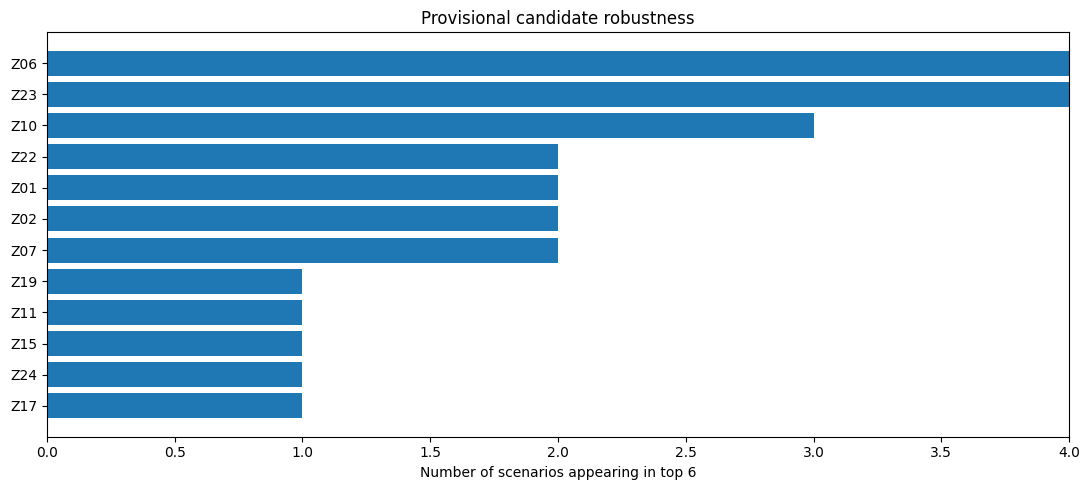

In [6]:
print('다중 정류장 권역 상위 6개:')
display(agg[agg.type=='multi'].head(6)[['zone_id','names','top6_frequency','median_rank','daily_demand']])
print('단독 후보 상위 6개:')
display(agg[agg.type=='single'].head(6)[['zone_id','names','top6_frequency','median_rank','daily_demand']])
scenario_sets={key:set(agg.loc[agg[f'top6_{key}'],'zone_id']) for key in weights}
print('기준 상위6 교집합:',{k:len(v&scenario_sets['balanced']) for k,v in scenario_sets.items()})
fig,ax=plt.subplots(figsize=(11,5))
show=agg.sort_values('provisional_review_order').head(12)
ax.barh(show.zone_id.iloc[::-1],show.top6_frequency.iloc[::-1])
ax.set_xlim(0,4);ax.set_xlabel('Number of scenarios appearing in top 6');ax.set_title('Provisional candidate robustness')
fig.tight_layout();fig.savefig(OUT/'06_top6_frequency.png',dpi=170);plt.show()


## 7. 월별·시간대별 그래프

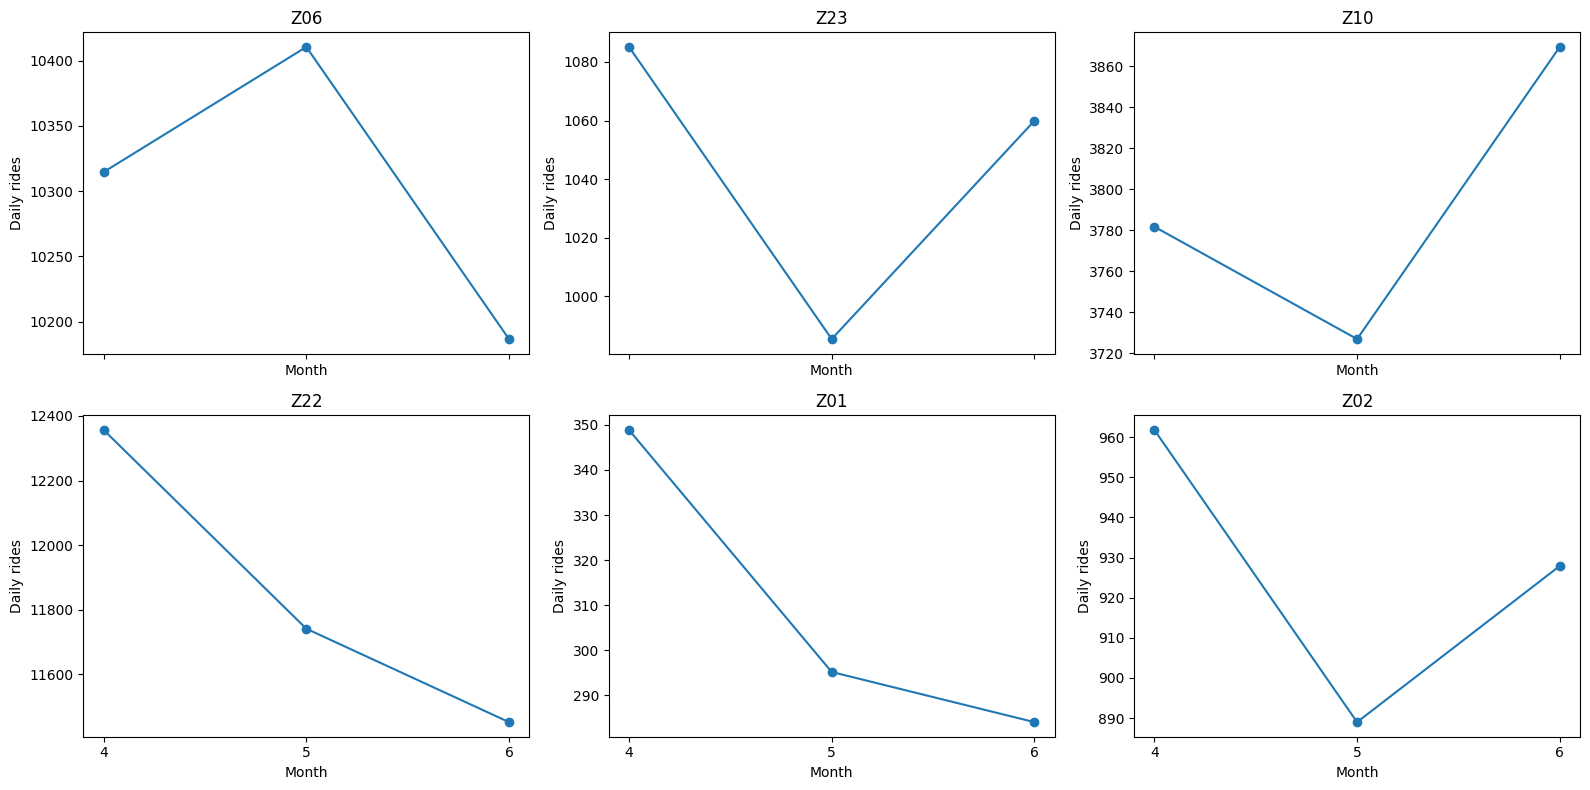

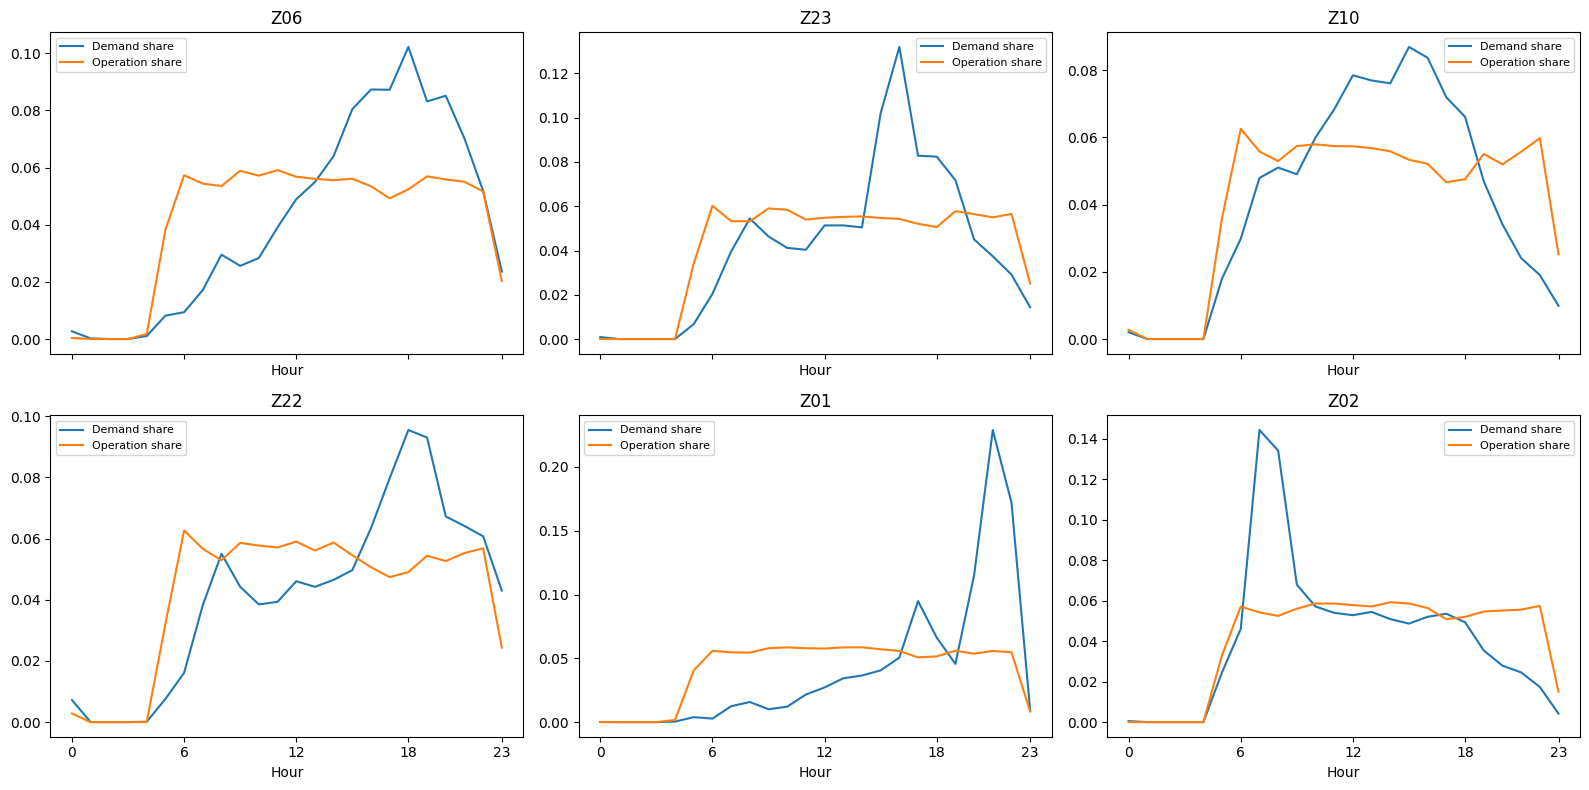

In [7]:
sel_ids=selected.zone_id.tolist()
fig,axes=plt.subplots(2,3,figsize=(16,8),sharex=True)
for ax,z in zip(axes.flat,sel_ids):
 q=monthly[monthly.zone_id==z].sort_values('month')
 ax.plot(q.month,q.daily_riders,marker='o',label='Daily boarding');ax.set_title(z)
 ax.set_xticks([4,5,6]);ax.set_xlabel('Month');ax.set_ylabel('Daily rides')
fig.tight_layout();fig.savefig(OUT/'07_top6_monthly_demand.png',dpi=150);plt.show()
fig,axes=plt.subplots(2,3,figsize=(16,8),sharex=True)
for ax,z in zip(axes.flat,sel_ids):
 q=hours[hours.zone_id==z].sort_values('hour')
 ax.plot(q.hour,q.demand_share,label='Demand share')
 ax.plot(q.hour,q.supply_share,label='Operation share')
 ax.set_title(z);ax.set_xticks([0,6,12,18,23]);ax.set_xlabel('Hour');ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUT/'08_top6_hourly_shares.png',dpi=150);plt.show()


## 8. 분석 한계 및 저장
- 6월 11일 자료는 0으로 대체하지 않음.
- 권역은 STEP 6의 500m Complete Linkage를 **고정**한 상태에서 운영 특성을 평가. 다른 반경에서도 후보가 유지되는지 추가 결합 검증 필요.
- 공간 유효성 미확인 37개 정류장명은 별도 추가 검토 대상으로 남음.
- 노선 수는 정류장별 중복 제거된 **권역 고유 노선 수가 아니므로** 이번 점수 가중치에 사용하지 않음.
- 별도의 OD·대기시간·정원 자료 없이 I-MOD 신규 호출 수요나 실제 공급 부족을 확정할 수 없음.

In [8]:
audit=pd.DataFrame([{'all_station_names':hourly.station_name.nunique(),
 'input_candidate_stop_names':len(assign), 'candidate_units':agg.zone_id.nunique(),
 'multi_zones':sum(agg.type=='multi'),'single_zones':sum(agg.type=='single'),
 'monthly_days':str(month_days.to_dict()),'top6_count':len(selected),
 'note':'Relative-gap and percentile screening only; no observed unmet demand.'}])
audit.to_csv(OUT/'09_audit_summary.csv',index=False,encoding='utf-8-sig')
zip_path=Path('Michuhol_IMOD_STEP7_Operational_Screening_Results.zip')
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
 for f in sorted(OUT.iterdir()):z.write(f,arcname=f.name)
print('결과 저장:',zip_path, '| 파일 개수:',len(list(OUT.iterdir())))
try:
 from google.colab import files
 files.download(str(zip_path))
except ImportError:pass


결과 저장: Michuhol_IMOD_STEP7_Operational_Screening_Results.zip | 파일 개수: 9


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>